# Flight data and model accuracy

**The question:** can we tell, early enough to act, which tight connections at Hong Kong will break?

This notebook walks through the evidence in four steps:

1. **The flight data:** what 91 real days at Hong Kong look like.
2. **Tight connections:** how many there are, how often they break, and what a miss costs.
3. **Accuracy:** how well the engine predicts breaks, a day ahead and 90 minutes before landing.
4. **What each ingredient added:** the schedule, the delay history, the in-flight estimate, and the two fixes the
   backtest led to.

**What "the model" is.** There is no trained machine-learning model. The engine is a simulation: for each
connection it draws 1,000 possible outcomes (when the inbound reaches the gate, how long this passenger takes to
get across the terminal, when the outbound gate closes) and reports the share in which the passenger is too late.
Its inputs are measured from real data where we have it and are documented assumptions where we do not.

**Key findings**

- **The data is large and real.** 31,243 Cathay flights at Hong Kong over 91 days (77,919 flights for all
  airlines). The median Cathay arrival is 8 minutes early; one in ten is 27 minutes late or more.
- **Tight connections are common and fragile.** 69,124 tight Cathay connections, about 760 a day. 12.5% break:
  23% at 50 to 54 minutes, 5% at 85 to 89, and 19.5% on disrupted days against 11.5% on normal days.
- **A miss is expensive.** The next Cathay flight to the same city is a median 8.6 hours later; 58% of misses
  mean six hours or more.
- **A fixed rule sees none of it.** The 38-minute minimum-connection rule flags 0% of these breaks.
- **A day ahead, little can be known** (AUC 0.68, barely better than the scheduled gap alone at 0.66).
- **In flight, the engine is sharp.** 90 minutes before landing it catches 93% of breaks while flagging 22% of
  tight connections (AUC 0.97). Half of its flags are real breaks.
- **Its percentages are honest, and lean cautious.** Where it says 54%, 44% broke.
- **It degrades gently.** If in-flight estimates were twice as wrong as measured (±22 minutes instead of ±11),
  it would still catch 90% of breaks, with more false alarms (33% flagged).
- **For passengers.** On the scenario evening 145 missed. Flow gave 94 a plan before landing and wrongly moved
  nobody; an automatic rebooking rule planned for 75 and wrongly moved 23.


**Labels used below**

| Label | Meaning |
|---|---|
| REAL | Public data: HKIA flight records, OAG status history |
| ASSUMED | A documented assumption, e.g. transfer times in `config/engine.yaml` |
| SIMULATED | Real flight timing combined with assumed transfer times |
| SYNTHETIC | Invented passengers, sized from published load and transfer figures |

In [1]:
import os
os.environ["OFFLINE"] = "1"   # nothing in this notebook calls an outside service

import json
from datetime import timedelta

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from flowcore.config import get_settings
from flowcore.scenario import load_scenario
from flowresearch import backtest, charts, eda

charts.use_style()
pd.set_option("display.width", 160)
root = get_settings().repo_root
policy = yaml.safe_load((root / "config" / "policy.yaml").read_text())
flights = load_scenario("2026-10-22-evening")["flights"]

## 1. The flight data (REAL)

Hong Kong airport publishes every past passenger flight for the last 91 days: scheduled time, actual time at the
gate, stand, gate and cancellations. We stored every day in the window.

In [2]:
hk = eda.hkia_flights()
cx = hk[hk["carrier"] == "CX"]
flown = cx[~cx["cancelled"] & cx["delay"].notna()]
overview = pd.DataFrame({
    "all airlines": [len(hk), hk["sched_date"].nunique(), int(hk["cancelled"].sum())],
    "Cathay-operated": [len(cx), cx["sched_date"].nunique(), int(cx["cancelled"].sum())],
}, index=["passenger flights", "days", "cancelled"])
print(f"{hk['sched_date'].min():%d %b %Y} to {hk['sched_date'].max():%d %b %Y}; "
      f"Cathay: {len(cx[cx['kind'] == 'arr']):,} arrivals, {len(cx[cx['kind'] == 'dep']):,} departures, "
      f"about {len(cx) / cx['sched_date'].nunique():.0f} flights a day")
overview

15 Aug 2026 to 14 Nov 2026; Cathay: 15,617 arrivals, 15,626 departures, about 343 flights a day


,all airlines,Cathay-operated
passenger flights,77919,31243
days,92,91
cancelled,397,114


### How late do Cathay flights run?

Delay is the actual gate time minus the scheduled time. Arrivals matter most for connections: a late arrival
eats the transfer time directly.

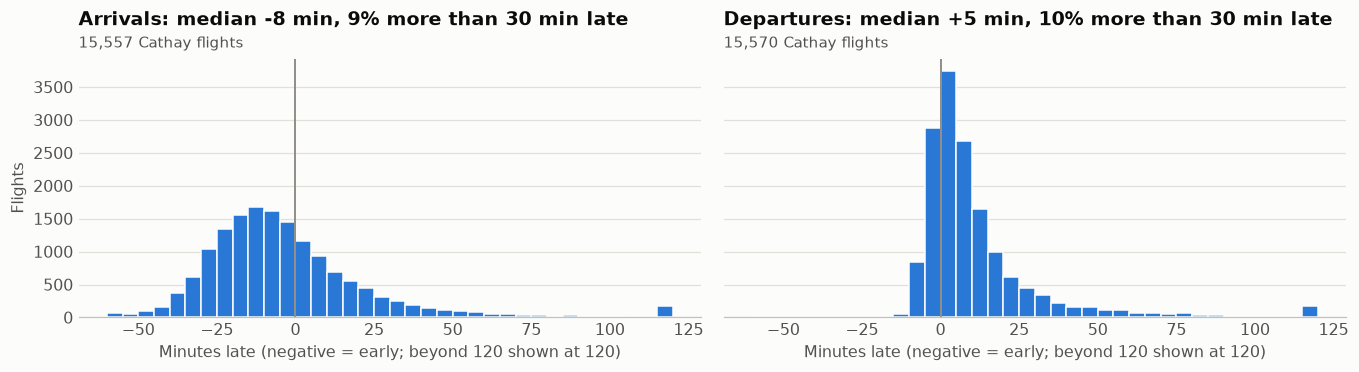

,arrivals,departures
count,15557.0,15570.0
mean,-1.1,11.7
std,55.7,27.3
min,-91.0,-14.0
10%,-29.0,-4.0
50%,-8.0,5.0
90%,27.0,32.0
95%,46.0,52.0
max,1896.0,1014.0


In [3]:
arr, dep = flown[flown["kind"] == "arr"]["delay"], flown[flown["kind"] == "dep"]["delay"]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.5), sharey=True)
for ax, delays, what in [(axes[0], arr, "Arrivals"), (axes[1], dep, "Departures")]:
    ax.hist(delays.clip(-60, 120), bins=np.arange(-60, 125, 5), color=charts.BLUE, edgecolor=charts.SURFACE, linewidth=1)
    ax.axvline(0, color=charts.GREY, linewidth=1.2)
    ax.set_xlabel("Minutes late (negative = early; beyond 120 shown at 120)")
    charts.title(ax, f"{what}: median {delays.median():+.0f} min, {(delays > 30).mean():.0%} more than 30 min late",
                 f"{len(delays):,} Cathay flights")
axes[0].set_ylabel("Flights")
plt.tight_layout(); plt.show()
pd.DataFrame({"arrivals": arr.describe(percentiles=[.1, .5, .9, .95]), "departures": dep.describe(percentiles=[.1, .5, .9, .95])}).round(1)

**Reading it.** Arrivals are often early, and the spread is wide in both directions. Departures almost never leave
early. Both facts shape the engine: an early arrival gives a passenger extra time, and a late departure gives
extra time too (the gate closes later), but only if the airline publishes it.

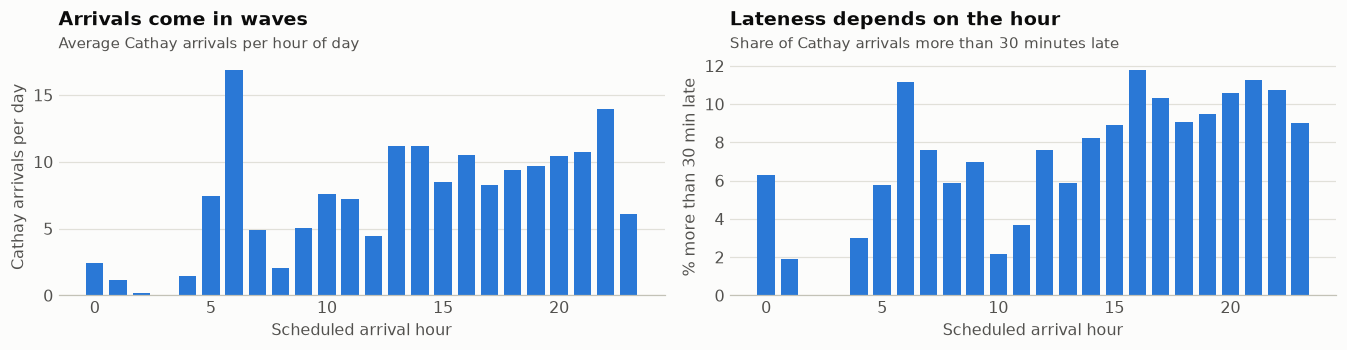

In [4]:
by_hour = flown[flown["kind"] == "arr"].groupby("hour")["delay"].agg(
    flights="size", median="median", late_share=lambda d: (d > 30).mean())
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.3))
axes[0].bar(by_hour.index, by_hour["flights"] / cx["sched_date"].nunique(), color=charts.BLUE, width=0.75)
axes[0].set_xlabel("Scheduled arrival hour"); axes[0].set_ylabel("Cathay arrivals per day")
charts.title(axes[0], "Arrivals come in waves", "Average Cathay arrivals per hour of day")
axes[1].bar(by_hour.index, by_hour["late_share"] * 100, color=charts.BLUE, width=0.75)
axes[1].set_xlabel("Scheduled arrival hour"); axes[1].set_ylabel("% more than 30 min late")
charts.title(axes[1], "Lateness depends on the hour", "Share of Cathay arrivals more than 30 minutes late")
plt.tight_layout(); plt.show()

### Disrupted days

Some days are much worse than others. We call a day **disrupted** if its share of Cathay arrivals more than 30
minutes late is in the top tenth of days, or 10 or more Cathay flights were cancelled (our definition, ASSUMED).

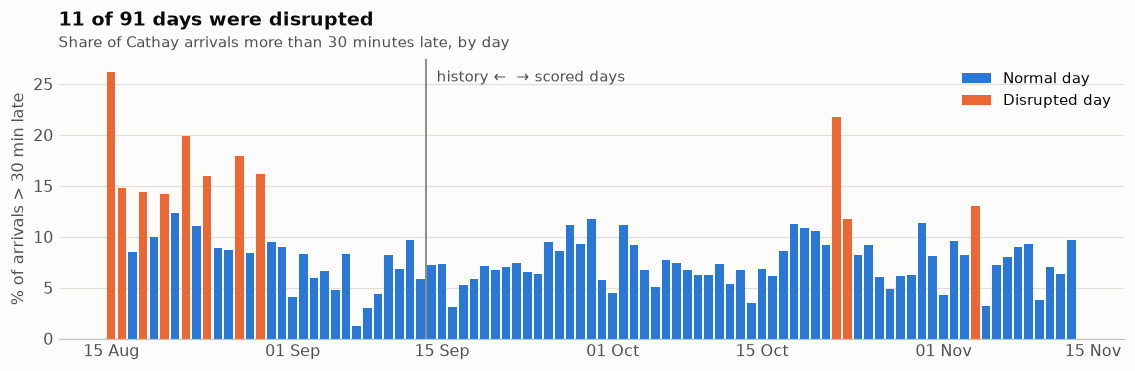

Disrupted days: 15 Aug, 16 Aug, 18 Aug, 20 Aug, 22 Aug, 24 Aug, 27 Aug, 29 Aug, 22 Oct, 23 Oct, 04 Nov


In [5]:
records, context = backtest.build_records()
df = pd.DataFrame(records)
df["test"] = df["day"] >= context["split"]
disrupted = context["disrupted"]

daily = flown[flown["kind"] == "arr"].groupby("sched_date")["delay"].agg(late_share=lambda d: (d > 30).mean())
daily["cancelled"] = cx[cx["cancelled"]].groupby("sched_date").size().reindex(daily.index).fillna(0)
daily["disrupted"] = [day in disrupted for day in daily.index]
fig, ax = plt.subplots(figsize=(12.5, 3.3))
for flag, colour, name in [(False, charts.BLUE, "Normal day"), (True, charts.ORANGE, "Disrupted day")]:
    part = daily[daily["disrupted"] == flag]
    ax.bar(pd.to_datetime(part.index), part["late_share"] * 100, color=colour, width=0.8, label=name)
ax.axvline(pd.Timestamp(context["split"]) - pd.Timedelta(hours=12), color=charts.GREY, linewidth=1.2)
ax.text(pd.Timestamp(context["split"]) + pd.Timedelta(days=0.5), ax.get_ylim()[1] * 0.92,
        "history ←  → scored days", fontsize=9.5, color=charts.SECOND_INK)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
ax.set_ylabel("% of arrivals > 30 min late"); ax.legend(loc="upper right")
charts.title(ax, f"{len(disrupted)} of {len(daily)} days were disrupted", "Share of Cathay arrivals more than 30 minutes late, by day")
plt.show()
print("Disrupted days:", ", ".join(f"{d:%d %b}" for d in sorted(disrupted)))

## 2. Tight connections

A **tight connection** is a Cathay arrival and a Cathay departure 50 to 89 minutes apart on the schedule, on a
plausible route, with neither flight cancelled. Every such pair in the 91 days is one row.

**"Broke"** means: the real gate-arrival time, plus one passenger's transfer time, is later than the real gate
close (15 minutes before departure). The flight times are REAL. The transfer time is drawn from the engine's
transfer model (ASSUMED), because nobody publishes whether real passengers made it. So break rates are SIMULATED.

69,124 tight connections over 91 days (760 a day); 12.5% broke


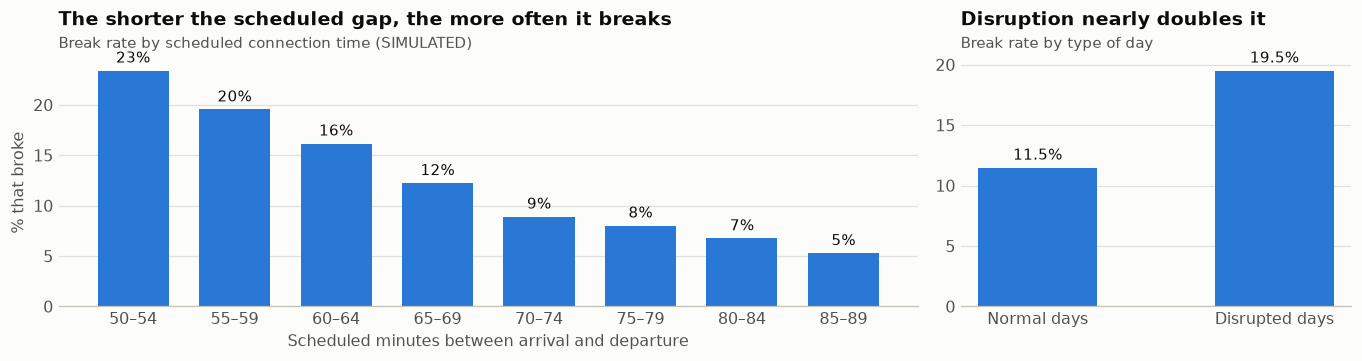

gap_band,50–54,55–59,60–64,65–69,70–74,75–79,80–84,85–89
connections,8728.000,7837.000,8456.000,9012.000,9410.000,9659.00,8168.000,7854.000
break_rate,0.234,0.195,0.162,0.122,0.089,0.08,0.068,0.053


In [6]:
print(f"{len(df):,} tight connections over {df['day'].nunique()} days ({len(df) / df['day'].nunique():.0f} a day); "
      f"{df['broke'].mean():.1%} broke")
df["gap_band"] = pd.cut(df["gap"], bins=[50, 55, 60, 65, 70, 75, 80, 85, 90], right=False,
                        labels=["50–54", "55–59", "60–64", "65–69", "70–74", "75–79", "80–84", "85–89"])
by_gap = df.groupby("gap_band", observed=True)["broke"].agg(["size", "mean"])
by_day = df.groupby("disrupted")["broke"].agg(["size", "mean"])
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.4), gridspec_kw={"width_ratios": [2.2, 1]})
bars = axes[0].bar(by_gap.index.astype(str), by_gap["mean"] * 100, color=charts.BLUE, width=0.7)
axes[0].bar_label(bars, labels=[f"{v:.0%}" for v in by_gap["mean"]], padding=3, fontsize=9.5, color=charts.INK)
axes[0].set_xlabel("Scheduled minutes between arrival and departure"); axes[0].set_ylabel("% that broke")
charts.title(axes[0], "The shorter the scheduled gap, the more often it breaks", "Break rate by scheduled connection time (SIMULATED)")
bars = axes[1].bar(["Normal days", "Disrupted days"], by_day["mean"] * 100, color=charts.BLUE, width=0.5)
axes[1].bar_label(bars, labels=[f"{v:.1%}" for v in by_day["mean"]], padding=3, fontsize=9.5, color=charts.INK)
charts.title(axes[1], "Disruption nearly doubles it", "Break rate by type of day")
plt.tight_layout(); plt.show()
by_gap.rename(columns={"size": "connections", "mean": "break_rate"}).round(3).T

### Why a break happens: the arrival delay decides

Among tight connections, the inbound flight's delay separates the ones that held from the ones that broke.

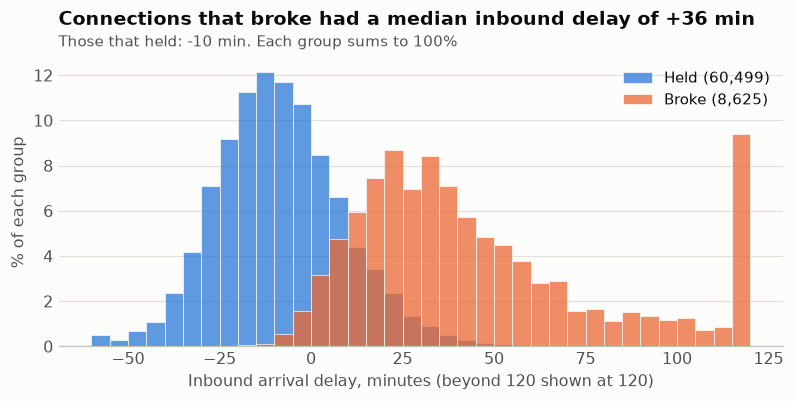

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
bins = np.arange(-60, 125, 5)
for flag, colour, name in [(False, charts.BLUE, "Held"), (True, charts.ORANGE, "Broke")]:
    part = df[df["broke"] == flag]["inbound_delay"].clip(-60, 120)
    ax.hist(part, bins=bins, weights=np.full(len(part), 100 / len(part)), color=colour, alpha=0.75,
            edgecolor=charts.SURFACE, linewidth=0.6, label=f"{name} ({len(part):,})")
ax.set_xlabel("Inbound arrival delay, minutes (beyond 120 shown at 120)"); ax.set_ylabel("% of each group")
ax.legend(loc="upper right")
charts.title(ax, f"Connections that broke had a median inbound delay of {df[df['broke']]['inbound_delay'].median():+.0f} min",
             f"Those that held: {df[~df['broke']]['inbound_delay'].median():+.0f} min. Each group sums to 100%")
plt.show()

### What a miss costs (REAL)

For every connection that broke, how long until the next Cathay flight to the same city? This uses the real
schedule only.

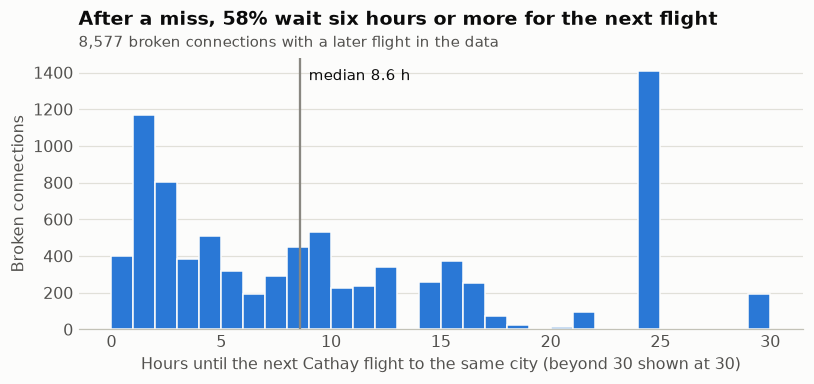

In [8]:
waits = df[df["broke"] & df["next_hours"].notna()]["next_hours"]
fig, ax = plt.subplots(figsize=(8.5, 3.2))
ax.hist(waits.clip(0, 30), bins=np.arange(0, 31, 1), color=charts.BLUE, edgecolor=charts.SURFACE, linewidth=1)
ax.axvline(waits.median(), color=charts.GREY, linewidth=1.5)
ax.text(waits.median() + 0.4, ax.get_ylim()[1] * 0.92, f"median {waits.median():.1f} h", fontsize=9.5, color=charts.INK)
ax.set_xlabel("Hours until the next Cathay flight to the same city (beyond 30 shown at 30)"); ax.set_ylabel("Broken connections")
charts.title(ax, f"After a miss, {(waits >= 6).mean():.0%} wait six hours or more for the next flight",
             f"{len(waits):,} broken connections with a later flight in the data")
plt.show()

## 3. How good is the information we get in flight? (REAL)

The engine's best input is the airline's own estimate of when the inbound will reach the gate, published while
the flight is in the air (OAG status history). We pulled that history for the 30 Cathay arrivals of the scenario
evening and compared each estimate with what really happened.

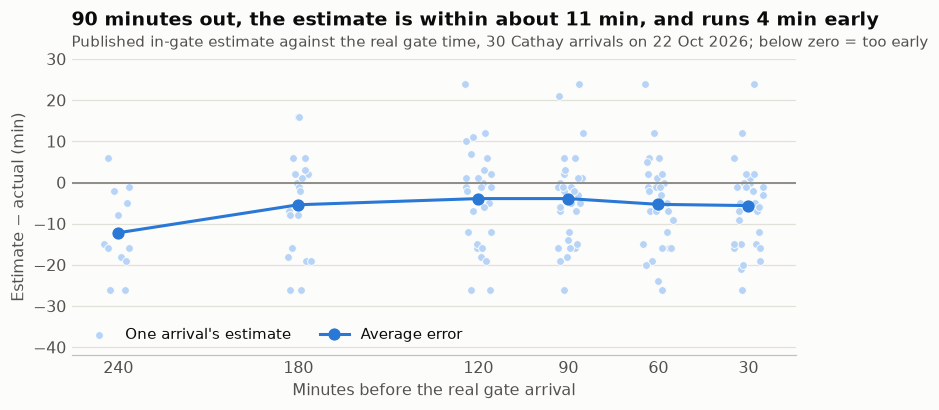

,flights,mean,sd,typical_miss
lead,,,,
240,12,-12.2,10.1,15.5
180,21,-5.4,12.4,8.0
120,27,-3.9,12.1,7.0
90,30,-3.9,11.3,6.0
60,30,-5.3,10.9,6.5
30,30,-5.6,10.7,6.5


In [9]:
errors = eda.estimate_errors_by_lead(flights)
by_lead = errors.groupby("lead")["error"].agg(flights="size", mean="mean", sd="std",
                                               typical_miss=lambda e: e.abs().median()).round(1)
fig, ax = plt.subplots(figsize=(8.5, 3.5))
jitter = np.random.default_rng(1).uniform(-5, 5, len(errors))
ax.scatter(errors["lead"] + jitter, errors["error"], s=26, color=charts.LIGHT_BLUE, edgecolor=charts.SURFACE, linewidth=0.6,
           label="One arrival's estimate")
ax.plot(by_lead.index, by_lead["mean"], color=charts.BLUE, marker="o", label="Average error")
ax.axhline(0, color=charts.GREY, linewidth=1.2)
ax.invert_xaxis(); ax.set_xticks(list(by_lead.index))
ax.set_xlabel("Minutes before the real gate arrival"); ax.set_ylabel("Estimate − actual (min)")
ax.set_ylim(-42, 30); ax.legend(loc="lower left", ncol=2)
at90 = by_lead.loc[90]
charts.title(ax, f"90 minutes out, the estimate is within about {at90['sd']:.0f} min, and runs {abs(at90['mean']):.0f} min early",
             "Published in-gate estimate against the real gate time, 30 Cathay arrivals on 22 Oct 2026; below zero = too early")
plt.show()
by_lead.sort_index(ascending=False)

**How the engine uses this.** It does not trust the published estimate blindly. It adds the average error back
(the estimates ran early) and spreads the arrival time by the measured error. This is a small sample from one
evening, and it is the first thing a larger OAG pull would firm up.

## 4. Accuracy

**The test is honest about time.** Delay histories come only from the first 30 days. Scores are reported only on
the 61 later days, which the engine never saw.

**Three ways to spot a break are compared:**

- **Fixed rule:** flag a connection if it is shorter than 38 minutes (8 to leave the aircraft, 15 to transfer, 15
  for gate close). A tight connection is 50 to 89 minutes by definition, so this rule flags none of them.
- **Engine, a day ahead:** the schedule plus the history of delays. Nothing about today's flight.
- **Engine, 90 minutes before landing:** adds an in-flight estimate that is exactly as wrong as the real OAG
  estimates measured above.

**How to read the chart.** Sort connections from riskiest to safest and flag from the top. The further a line
bends to the upper left, the more real breaks are caught for the same number of flags. The diagonal is guessing.

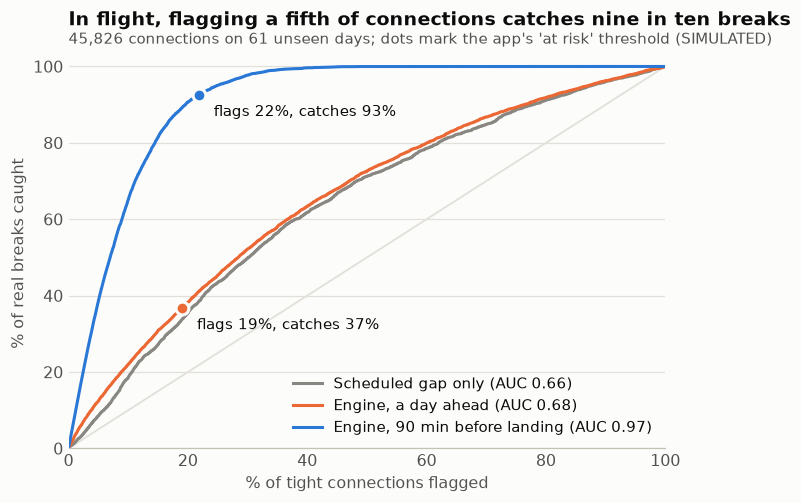

In [10]:
test = df[df["test"]]
labels = test["broke"].to_numpy()
series = [("Scheduled gap only", -test["gap"].to_numpy(), charts.GREY),
          ("Engine, a day ahead", test["p_day_before"].to_numpy(), charts.ORANGE),
          ("Engine, 90 min before landing", test["p_in_flight"].to_numpy(), charts.BLUE)]
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.plot([0, 100], [0, 100], color=charts.GRID, linewidth=1.2)
for name, scores, colour in series:
    flagged, caught = eda.catch_curve(scores, labels)
    ax.plot(flagged * 100, caught * 100, color=colour, label=f"{name} (AUC {backtest.auc(scores, labels):.2f})")
for name, scores, colour in series[1:]:
    flags = scores >= policy["tau_watch"]
    x, y = flags.mean() * 100, (flags & labels).sum() / labels.sum() * 100
    ax.scatter(x, y, s=70, color=colour, edgecolor=charts.SURFACE, linewidth=2, zorder=5)
    ax.annotate(f"flags {x:.0f}%, catches {y:.0f}%", (x, y), xytext=(10, -14), textcoords="offset points", fontsize=9.5, color=charts.INK)
ax.set_xlabel("% of tight connections flagged"); ax.set_ylabel("% of real breaks caught")
ax.set_xlim(0, 100); ax.set_ylim(0, 102); ax.legend(loc="lower right")
charts.title(ax, "In flight, flagging a fifth of connections catches nine in ten breaks",
             f"{len(test):,} connections on 61 unseen days; dots mark the app's 'at risk' threshold (SIMULATED)")
plt.show()

In [11]:
def score_row(name, scores):
    flags = scores >= policy["tau_watch"]
    caught = (flags & labels).sum()
    return {"forecast": name, "AUC": round(backtest.auc(scores, labels), 3),
            "flagged": f"{flags.mean():.1%}", "breaks caught": f"{caught / labels.sum():.1%}",
            "flags that were real breaks": f"{caught / max(flags.sum(), 1):.1%}"}

fixed = test["gap"].to_numpy() < context["config"]["baseline_r0_minutes"]
ladder = pd.DataFrame([
    {"forecast": "Fixed 38-minute rule", "AUC": "–", "flagged": f"{fixed.mean():.1%}",
     "breaks caught": f"{(fixed & labels).sum() / labels.sum():.1%}", "flags that were real breaks": "–"},
    {"forecast": "Scheduled gap only (ranking)", "AUC": round(backtest.auc(-test["gap"].to_numpy(), labels), 3),
     "flagged": "–", "breaks caught": "–", "flags that were real breaks": "–"},
    score_row("Engine, a day ahead", test["p_day_before"].to_numpy()),
    score_row("Engine, 90 min before landing", test["p_in_flight"].to_numpy()),
])
print(f"{len(test):,} test connections, {labels.sum():,} breaks ({labels.mean():.1%}). 'Flagged' = chance of missing at or above "
      f"{policy['tau_watch']:.0%}, the app's 'at risk' threshold.")
ladder

45,826 test connections, 5,471 breaks (11.9%). 'Flagged' = chance of missing at or above 20%, the app's 'at risk' threshold.


,forecast,AUC,flagged,breaks caught,flags that were real breaks
0,Fixed 38-minute rule,–,0.0%,0.0%,–
1,Scheduled gap only (ranking),0.66,–,–,–
2,"Engine, a day ahead",0.676,19.0%,36.8%,23.2%
3,"Engine, 90 min before landing",0.966,21.8%,92.6%,50.8%


**AUC in one sentence:** pick one connection that broke and one that held at random; AUC is the chance the engine
gave the broken one the higher risk. 0.5 is a coin flip, 1.0 is perfect.

**The honest reading.** A day ahead, nobody can know much: the engine is barely better than looking at the
scheduled gap. Once the flight is in the air, the picture is sharp. That is why the product acts in flight, not
at booking.

### Are the percentages themselves right?

When the engine says "40% chance of missing", do about 40% of those connections break? Each point below is a group
of connections with similar predicted risk. On the diagonal, the stated risk matches what happened.

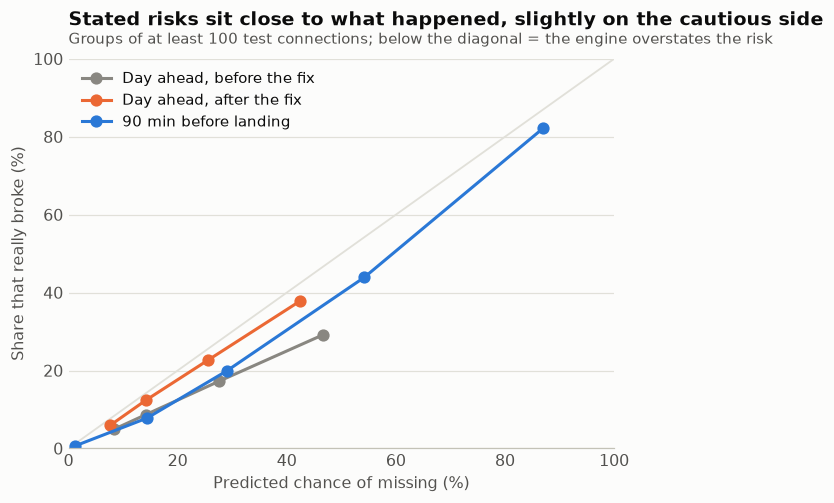

,from,to,pairs,predicted,observed,forecast
0,0.0,0.1,33022,0.011,0.006,90 min before landing
1,0.1,0.2,2820,0.144,0.078,90 min before landing
2,0.2,0.4,3172,0.290,0.199,90 min before landing
3,0.4,0.7,3032,0.542,0.439,90 min before landing
4,0.7,1.0,3780,0.870,0.822,90 min before landing


In [12]:
fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.plot([0, 100], [0, 100], color=charts.GRID, linewidth=1.2)
for name, column, colour in [("Day ahead, before the fix", "p", charts.GREY), ("Day ahead, after the fix", "p_day_before", charts.ORANGE),
                             ("90 min before landing", "p_in_flight", charts.BLUE)]:
    rows = pd.DataFrame(backtest.calibration(test[column].to_numpy(), labels))
    rows = rows[rows["pairs"] >= 100]
    ax.plot(rows["predicted"] * 100, rows["observed"] * 100, color=colour, marker="o", label=name)
ax.set_xlabel("Predicted chance of missing (%)"); ax.set_ylabel("Share that really broke (%)")
ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.legend(loc="upper left")
charts.title(ax, "Stated risks sit close to what happened, slightly on the cautious side",
             "Groups of at least 100 test connections; below the diagonal = the engine overstates the risk")
plt.show()
pd.DataFrame(backtest.calibration(test["p_in_flight"].to_numpy(), labels)).assign(forecast="90 min before landing")

The engine leans cautious: it states a slightly higher risk than what happened. For a tool that holds a backup
seat without changing anything for the passenger, erring towards caution is the cheaper mistake.

## 5. What each ingredient added

### The two fixes the backtest led to

1. **A day ahead, the first version was overconfident.** It ignored that outbound flights often leave late, which
   gives the passenger extra time. Adding the history of departure delays brought its stated risks back towards
   what happened (grey to orange in the chart above).
2. **In flight, the first version trusted the published estimate too much.** It now uses the measured error
   (about ±11 minutes, 4 minutes early).

Together, the two fixes moved Mei's risk in the demo, 90 minutes before landing, from 56% to 42%.

In [13]:
before_after = pd.DataFrame([
    {"day-ahead forecast": name, "AUC": round(backtest.auc(test[col].to_numpy(), labels), 3),
     "Brier score (lower is better)": round(float(np.mean((test[col].to_numpy() - labels) ** 2)), 4),
     "flagged at risk": f"{(test[col] >= policy['tau_watch']).mean():.1%}",
     "average predicted": f"{test[col].mean():.1%}", "really broke": f"{labels.mean():.1%}"}
    for name, col in [("Before the fix", "p"), ("After the fix (late departures counted)", "p_day_before")]])
before_after

,day-ahead forecast,AUC,Brier score (lower is better),flagged at risk,average predicted,really broke
0,Before the fix,0.675,0.1075,38.6%,19.3%,11.9%
1,After the fix (late departures counted),0.676,0.1008,19.0%,13.9%,11.9%


### How much does the accuracy of the in-flight estimate matter?

The same backtest, re-run with the in-flight estimate made better or worse than what we measured. Everything
else, including the random draws, is identical.

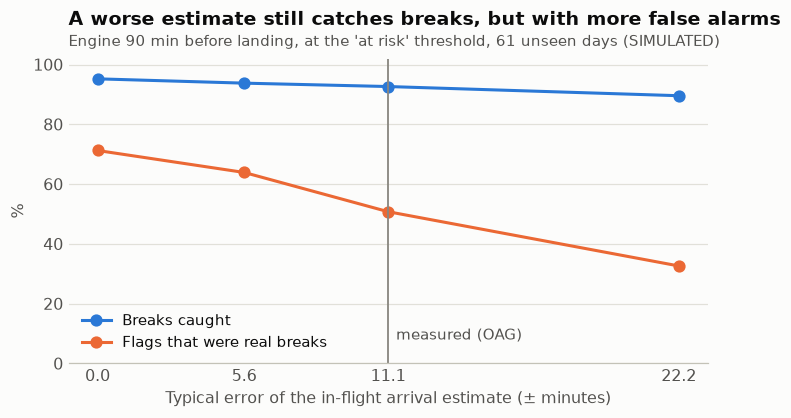

,estimate error (± min),AUC,flagged,breaks caught,flags that were real breaks
0,0.0,0.987,16.0,95.2,71.2
1,5.6,0.982,17.5,93.8,63.9
2,11.1,0.966,21.8,92.6,50.8
3,22.2,0.913,32.8,89.6,32.6


In [14]:
def in_flight_scores(scale):
    rows = records if scale == 1.0 else backtest.build_records(error_scale=scale)[0]
    part = pd.DataFrame(rows)
    part = part[part["day"] >= context["split"]]
    scores, truth = part["p_in_flight"].to_numpy(), part["broke"].to_numpy()
    flags = scores >= policy["tau_watch"]
    return {"estimate error (± min)": round(float(np.std(context["oag_errors"])) * scale, 1),
            "AUC": round(backtest.auc(scores, truth), 3), "flagged": flags.mean() * 100,
            "breaks caught": (flags & truth).sum() / truth.sum() * 100,
            "flags that were real breaks": (flags & truth).sum() / flags.sum() * 100}

sensitivity = pd.DataFrame([in_flight_scores(scale) for scale in (0.0, 0.5, 1.0, 2.0)])
fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = sensitivity["estimate error (± min)"]
ax.plot(x, sensitivity["breaks caught"], color=charts.BLUE, marker="o", label="Breaks caught")
ax.plot(x, sensitivity["flags that were real breaks"], color=charts.ORANGE, marker="o", label="Flags that were real breaks")
ax.axvline(x[2], color=charts.GREY, linewidth=1.2)
ax.text(x[2] + 0.3, 8, "measured (OAG)", fontsize=9.5, color=charts.SECOND_INK)
ax.set_ylim(0, 102); ax.set_xticks(list(x)); ax.set_xlabel("Typical error of the in-flight arrival estimate (± minutes)"); ax.set_ylabel("%")
ax.legend(loc="lower left")
charts.title(ax, "A worse estimate still catches breaks, but with more false alarms",
             "Engine 90 min before landing, at the 'at risk' threshold, 61 unseen days (SIMULATED)")
plt.show()
sensitivity.round({"AUC": 3, "flagged": 1, "breaks caught": 1, "flags that were real breaks": 1})

## 6. From prediction to people: the scenario evening

The replay of Thursday 22 October 2026 turns predictions into actions for 1,950 synthetic passengers on real
flights. Three policies are compared on the passengers who really missed their connection.

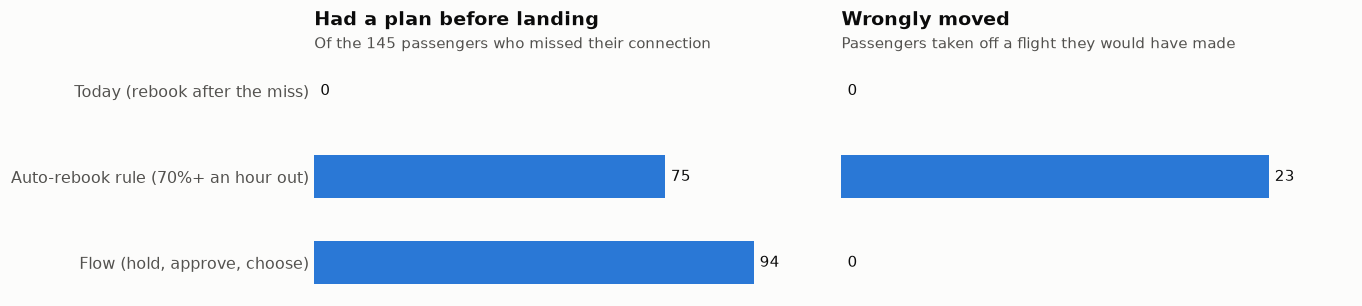

,policy,plan before landing,wrongly moved
0,Today (rebook after the miss),0,0
1,Auto-rebook rule (70%+ an hour out),75,23
2,"Flow (hold, approve, choose)",94,0


In [15]:
evidence = {item["id"]: item for item in json.loads((root / "data" / "evidence.json").read_text())}
value = lambda key: evidence[key]["value"]
policies = pd.DataFrame({
    "policy": ["Today (rebook after the miss)", "Auto-rebook rule (70%+ an hour out)", "Flow (hold, approve, choose)"],
    "plan before landing": [value("today_plan_before_landing"), value("auto_plan_before_landing"), value("flow_plan_before_landing")],
    "wrongly moved": [0, value("auto_wrong_bumps"), value("flow_wrong_bumps")]})
fig, axes = plt.subplots(1, 2, figsize=(12.5, 2.9))
for ax, column, text, note in [
        (axes[0], "plan before landing", "Had a plan before landing",
         f"Of the {value('missed_passengers'):.0f} passengers who missed their connection"),
        (axes[1], "wrongly moved", "Wrongly moved", "Passengers taken off a flight they would have made")]:
    bars = ax.barh(policies["policy"][::-1], policies[column][::-1], color=charts.BLUE, height=0.5)
    ax.bar_label(bars, padding=4, fontsize=10, color=charts.INK, fmt="%.0f")
    ax.grid(False); ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.set_xlim(0, policies[column].max() * 1.15 + 1)
    charts.title(ax, text, note)
axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()
policies

Flow gets more passengers a plan than the automatic rule, and moves nobody who would have made it, because a
held seat is only confirmed by the passenger's choice or after a real miss.

## Limits, stated plainly

- **No real passenger outcomes.** "Broke" combines real flight times with an assumed transfer time. The backtest
  proves the timing forecast, not the transfer model. The same transfer model is used to make the forecast and
  to decide what counts as a break, so these scores are an upper bound on what real passengers would show.
- **The in-flight error comes from 30 flights on one evening.** The sensitivity chart shows what happens if the
  true error is larger.
- **The in-flight forecast is simulated for most days.** We have real OAG histories for one evening; for the
  other days the estimate is the real arrival time plus an error drawn from the measured ones.
- **No trained model.** Delays come straight from the history of past delays. That keeps every number
  explainable, and it leaves room for a learned delay model later.
- **Disrupted days are our own definition,** and the window has no typhoon.

**What Cathay's own data would replace:** real connecting-passenger lists (who is on which connection), measured
transfer times, real seat inventory, and misconnection records to score against.